# Social Media Engagement Analytics Using Python


In [1]:
import pandas as pd
import numpy as np

#### Task 1  Data Import & Setup

In [2]:
df=pd.read_csv(r"C:\Users\Lenovo\Downloads\social_media_engagement_5000.csv")

##### The Data Under Analysis

In [5]:
df

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,25-06-2022,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,18-11-2022,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,NaN,167.0,7466,23680,06-04-2023,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,16-05-2022,183295,False,tablet,positive,#reels #love #fitness,0.223518


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   str    
 3   country           5000 non-null   str    
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   str    
 6   post_category     5000 non-null   str    
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   str    
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   str    
 16  sentiment         4850 non-null   str    
 17  hashta

##### The posted_at column is a string. Converting it to date datatype.

In [3]:
df["posted_at"] = pd.to_datetime(df["posted_at"], format="%d-%m-%Y")

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               4850 non-null   float64       
 2   gender            4850 non-null   str           
 3   country           5000 non-null   str           
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   str           
 6   post_category     5000 non-null   str           
 7   likes             4850 non-null   float64       
 8   comments          4850 non-null   float64       
 9   shares            4850 non-null   float64       
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[us]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 non-null   b

##### fixed data type issues

##### Basic array operations

In [7]:
Likes=df["likes"].to_numpy()
Ages=df["age"].to_numpy()
print("Mean_likes:",np.nanmean(Likes))
print("Minimum like:",np.nanmin(Likes))
print("Maximum like:",np.nanmax(Likes))
print("Mean_age:",np.nanmean(Ages))
print("Minimum age:",np.nanmin(Ages))
print("Maximum age:",np.nanmax(Ages))

Mean_likes: 10107.043711340206
Minimum like: 10.0
Maximum like: 19998.0
Mean_age: 38.454020618556704
Minimum age: 13.0
Maximum age: 64.0


##### 13 year old is the youngest user. Finding his post category.

In [8]:
inx=np.argmin(Ages)

In [11]:
postcat=df["post_category"].to_numpy()

In [12]:
print(postcat[inx])

fitness


##### Finding maximum amd minimum like earning post type  to know high and low engaging post type.

In [13]:
idx = np.argmin(Likes)

In [14]:
genre=df["post_type"].to_numpy()

In [15]:
print(genre[idx])

image


In [16]:
ind=np.argmax(Likes)

In [16]:
print(genre[ind])

image


#### Task 2 Data Cleaning

#### a) Cleaning missing data

In [17]:
df.isnull().sum()

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

##### Detected missing values

##### Using fillna , filled te categorical missing values to "Unkown" to maintain data quality and filled numerical nulls using first appearing mode.

In [4]:
df[["gender","sentiment"]]=df[["gender","sentiment"]].fillna("Unknown")

In [5]:
df[["age","likes","shares","comments"]]=df[["age","likes","shares","comments"]].fillna(df[["age","likes","shares","comments"]].mode().iloc[0])

In [6]:
df.isnull().sum()

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64

##### Eliminated all nulls

#### b) Duplicate Handling

In [20]:
print(df.duplicated().sum())

0


###### There are no duplicates . If there were ,i would have used  df.drop_duplicates()

#### c) Data Formatting

##### Data types were already checked in the intial stage and incorrect ones were converted.

In [27]:
for col in ["gender","post_type","post_category","is_verified","device_type","sentiment"]:
    print(df[col].value_counts(dropna=False))

gender
Male       1699
Other      1581
Female     1570
Unknown     150
Name: count, dtype: int64
post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64
post_category
fitness      675
tech         665
music        635
education    631
lifestyle    607
travel       600
fashion      594
food         593
Name: count, dtype: int64
is_verified
False    4517
True      483
Name: count, dtype: int64
device_type
mobile     1684
tablet     1658
desktop    1658
Name: count, dtype: int64
sentiment
positive    2363
neutral     1527
negative     960
Unknown      150
Name: count, dtype: int64


##### Categories are already standardized. 

In [23]:
print(df[["likes", "comments", "shares"]].describe())

              likes     comments       shares
count   5000.000000  5000.000000  5000.000000
mean    9998.412400  1545.149800   976.690600
std     5735.658626   890.548991   589.603387
min       10.000000     0.000000     0.000000
25%     5235.000000   792.000000   447.750000
50%     9776.000000  1540.000000   981.500000
75%    14959.000000  2323.000000  1483.000000
max    19998.000000  2999.000000  1999.000000


##### Likes are the dominant form of engagement, averaging 9998 per post. The data is showing a uniform distribution.

In [28]:
engagement_cols = ["likes", "comments", "shares"]
for col in engagement_cols:
    print(f"{col}:")
    print("Negative values:", (df[col] < 0).sum())

likes:
Negative values: 0
comments:
Negative values: 0
shares:
Negative values: 0


##### No unrealistic values present 

#### d) Feature cleaning

###### Extracting hashtag counts

In [35]:
df["hashtag_count"]=df["hashtags"].str.findall(r'#\w+').str.len()

In [41]:
print(df[["hashtags", "hashtag_count"]].head(10))

                  hashtags  hashtag_count
0    #foodie #travel #love              3
1                 #fitness              1
2                  #foodie              1
3      #music #foodie #fun              3
4                  #travel              1
5                 #fitness              1
6                   #music              1
7  #travel #music #fitness              3
8     #music #fun #fitness              3
9         #lifestyle #love              2


##### Hashtag counts varies as 3, 1,2 per post.

In [42]:
print(df[["hashtags", "hashtag_count"]].sort_values(by="hashtag_count", ascending=False).head(3))

                     hashtags  hashtag_count
3         #music #foodie #fun              3
3321      #love #travel #tech              3
3350  #fun #lifestyle #travel              3


####  Users have used a maximum of 3 hashtags per post.

#### cleaning sentiment labels

In [9]:
df["sentiment"] = df["sentiment"].str.strip().str.capitalize()

In [10]:
df["sentiment"].value_counts()

sentiment
Positive    2363
Neutral     1527
Negative     960
Unknown      150
Name: count, dtype: int64

#### Task 3 Data Exploration using Pandas

#### viewing dataset structure

In [43]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,mobile,Negative,#foodie #travel #love,0.190862,3
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,mobile,Negative,#fitness,0.201493,1
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,tablet,Positive,#foodie,0.137345,1
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,2023-02-12,480212,False,mobile,Negative,#music #foodie #fun,0.106195,3
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,2023-05-23,383936,False,mobile,Negative,#travel,2.777372,1


In [44]:
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,2022-06-25,646147,False,mobile,Positive,#travel #fun,0.466761,2
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,2022-11-18,584603,False,desktop,Negative,#foodie #reels,0.621155,2
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,2934.0,167.0,7466,23680,2023-04-06,483550,False,desktop,Positive,#lifestyle #tech,0.679688,2
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,2022-05-16,183295,False,tablet,Positive,#reels #love #fitness,0.223518,3
4999,73400,54.0,Other,Japan,712252,text,travel,14830.0,503.0,1798.0,3743,14234,2023-03-04,585760,False,desktop,Neutral,#foodie #lifestyle #fashion,1.203527,3


In [45]:
df.shape

(5000, 20)

In [46]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count'],
      dtype='str')

In [47]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   float64       
 2   gender            5000 non-null   str           
 3   country           5000 non-null   str           
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   str           
 6   post_category     5000 non-null   str           
 7   likes             5000 non-null   float64       
 8   comments          5000 non-null   float64       
 9   shares            5000 non-null   float64       
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[us]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 non-null   b

In [37]:
df.dtypes

user_id                      int64
age                        float64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                   string
hashtags                       str
engagement_rate            float64
hashtag_count                int64
dtype: object

#### Summary statistics

In [48]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.200400,548042.909000,9998.412400,1545.149800,976.690600,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.000000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,447.750000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,54374.500000,37.000000,548077.500000,9776.000000,1540.000000,981.500000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,14959.000000,2323.000000,1483.000000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.000000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26090.370121,14.757595,260646.957267,5735.658626,890.548991,589.603387,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853


#### Categorical distribution

In [51]:
for col in ["post_type", "post_category", "gender","country", "device_type", "sentiment"]:
    print(f"\n{col}")
    print("Unique values:", df[col].unique())
    print("valuecount:", df[col].value_counts())
    print("Number of categories:", df[col].nunique())
    print("Frequency:")
    print(df[col].value_counts(dropna=False))


post_type
Unique values: <ArrowStringArray>
['image', 'reel', 'text', 'video']
Length: 4, dtype: str
valuecount: post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64
Number of categories: 4
Frequency:
post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64

post_category
Unique values: <ArrowStringArray>
[  'fitness',      'food',      'tech',    'travel',   'fashion', 'lifestyle',
 'education',     'music']
Length: 8, dtype: str
valuecount: post_category
fitness      675
tech         665
music        635
education    631
lifestyle    607
travel       600
fashion      594
food         593
Name: count, dtype: int64
Number of categories: 8
Frequency:
post_category
fitness      675
tech         665
music        635
education    631
lifestyle    607
travel       600
fashion      594
food         593
Name: count, dtype: int64

gender
Unique values: <ArrowStringArray>
['Female', 'Male', 'Other', 'Unknown']
Length: 4,

#### Correlation matrix

In [10]:
numeric_df = df.select_dtypes(include="number")
correlation_matrix = numeric_df.corr()
print(correlation_matrix)

                   user_id       age   post_id     likes  comments    shares  \
user_id           1.000000 -0.006790  0.020051  0.024422 -0.026628  0.015279   
age              -0.006790  1.000000 -0.013047 -0.038930 -0.007489  0.012067   
post_id           0.020051 -0.013047  1.000000  0.013231 -0.010723  0.004168   
likes             0.024422 -0.038930  0.013231  1.000000 -0.020030  0.000155   
comments         -0.026628 -0.007489 -0.010723 -0.020030  1.000000  0.003638   
shares            0.015279  0.012067  0.004168  0.000155  0.003638  1.000000   
watch_time_sec   -0.016847  0.004641  0.018374  0.006624 -0.014429  0.015353   
impression_count  0.015326  0.013850 -0.007709  0.006096 -0.008255  0.004898   
follower_count    0.010124 -0.022412 -0.002844 -0.023470 -0.013778 -0.006643   
engagement_rate  -0.004282  0.008278  0.010139  0.094814 -0.001315  0.021465   
hashtag_count    -0.013692  0.006177  0.007344 -0.002675 -0.014960  0.019443   

                  watch_time_sec  impre

##### No variable in this dataset is showing a significant correlation . 

#### Summarizing matrix using groupby

In [11]:
avg_likes = df.groupby("post_type")["likes"].mean()
print(avg_likes)

post_type
image    10011.983160
reel      9910.851910
text      9986.766265
video    10088.140408
Name: likes, dtype: float64


##### Video has highest average likes.

In [12]:
avg_impressions = (df.groupby("country")["impression_count"].mean().sort_values(ascending=False))
print(avg_impressions)

country
India        52462.386916
France       51727.673387
USA          51263.872255
UK           51119.393509
Japan        49616.135593
Brazil       49193.174603
UAE          48928.413519
Canada       48703.150097
Germany      48605.406122
Australia    48346.383367
Name: impression_count, dtype: float64


##### Highest average impressions is for India.

In [13]:
avg_watchtime=df.groupby("post_category")["watch_time_sec"].mean()
print(avg_watchtime)

post_category
education    4064.865293
fashion      4070.067340
fitness      3982.051852
food         3989.146712
lifestyle    3995.995058
music        4106.696063
tech         3998.639098
travel       3906.835000
Name: watch_time_sec, dtype: float64


#### Highest avg watch time for Fashion category followed by Education.

#### Task 4 Data Wrangling 

##### Demonstrating concat

In [15]:
# splitting the dataframe and joining just to demonstrate
df_part1 = df.iloc[:2500]
df_part2 = df.iloc[2500:]
df_combined = pd.concat([df_part1, df_part2], ignore_index=True)
print(df_combined.shape)

(5000, 20)


#### New fields

In [14]:
df["engagement_score"] = (df["likes"] + df["comments"] + df["shares"])
print(df["engagement_score"].head())

0     8522.0
1    16163.0
2     6161.0
3     7482.0
4    16717.0
Name: engagement_score, dtype: float64


In [44]:
print(df["engagement_score"].max())

24740.0


In [45]:
idx = df["engagement_score"].idxmax()
print(df.loc[idx, ["engagement_score", "post_category", "post_type"]])

engagement_score      24740.0
post_category       lifestyle
post_type               video
Name: 3084, dtype: object


##### Lifestyle video has the highest Engagement score.

###### hashtag count already created

In [15]:
df["log_likes"] = np.log1p(df["likes"])
df["log_comments"] = np.log1p(df["comments"])
df["log_shares"] = np.log1p(df["shares"])
df["log_followers"] = np.log1p(df["follower_count"])

In [16]:
df[[
    "likes", "log_likes",
    "comments", "log_comments",
    "shares", "log_shares",
    "follower_count", "log_followers"
]].head()

,likes,log_likes,comments,log_comments,shares,log_shares,follower_count,log_followers
0,7011.0,8.855378,354.0,5.872118,1157.0,7.054450,81734,11.311238
1,11750.0,9.371694,2606.0,7.865955,1807.0,7.499977,5963,8.693497
2,4862.0,8.489411,344.0,5.843544,955.0,6.862758,501783,13.125925
3,5350.0,8.585039,1083.0,6.988413,1049.0,6.956545,480212,13.081985
4,12682.0,9.448018,2735.0,7.914252,1300.0,7.170888,383936,12.858234


##### As log transformation is an optional task . Not considering the trasormed columns for plotting.

#### group by summaries

post_type_summary = df.groupby("post_type").agg(
    post_count=("post_id", "count"),
    avg_likes=("likes", "mean"),
    avg_comments=("comments", "mean"),
    avg_shares=("shares", "mean"),
    avg_engagement_score=("engagement_score", "mean"))
print(post_type_summary.round(2))

##### Every post type performs neatly and there is no significant dip or peak

In [18]:
country_summary = df.groupby("country").agg(
    post_count=("post_id", "count"),
    avg_impressions=("impression_count", "mean"),
    avg_watch_time=("watch_time_sec", "mean"),
    avg_engagement_rate=("engagement_rate", "mean"))
print(country_summary.round(2))

           post_count  avg_impressions  avg_watch_time  avg_engagement_rate
country                                                                    
Australia         493         48346.38         4150.68                 1.32
Brazil            504         49193.17         4049.21                 1.54
Canada            513         48703.15         4003.70                 0.92
France            496         51727.67         3992.75                 1.15
Germany           490         48605.41         3976.38                 0.76
India             535         52462.39         4016.84                 0.66
Japan             472         49616.14         3878.39                 0.77
UAE               503         48928.41         4007.82                 1.11
UK                493         51119.39         4118.69                 0.85
USA               501         51263.87         3945.41                 0.58


###### A significant dip is only observed for USA engagement rate.

In [19]:
sentiment_summary = df.groupby("sentiment").agg(
    post_count=("post_id", "count"),
    avg_likes=("likes", "mean"),
    avg_comments=("comments", "mean"),
    avg_engagement_rate=("engagement_rate", "mean"))
print(sentiment_summary.round(2))

           post_count  avg_likes  avg_comments  avg_engagement_rate
sentiment                                                          
Negative          960   10094.99       1552.02                 1.04
Neutral          1527    9818.90       1566.99                 0.99
Positive         2363   10046.64       1531.05                 0.95
Unknown           150   10448.00       1500.97                 0.37


##### Positive sentimet posts are high but a slightly hike in engagement is noted for negative setiment.

#### Task 5  Statistical Analysis 

##### Mean,Median ,Mode,Std. Deviation,Variance

In [20]:
metrics = [
    "likes",
    "comments",
    "shares",
    "watch_time_sec",
    "engagement_rate",
    "follower_count"]
for col in metrics:
    print(f"\n--- {col} ---")
    print("Mean:", round(df[col].mean(), 2))
    print("Median:", round(df[col].median(), 2))
    print("Mode:", df[col].mode().head(3).tolist())
    print("Standard deviation:", round(df[col].std(), 2))
    print("Variance:", round(df[col].var(), 2))


--- likes ---
Mean: 9998.41
Median: 9776.0
Mode: [6486.0]
Standard deviation: 5735.66
Variance: 32897779.88

--- comments ---
Mean: 1545.15
Median: 1540.0
Mode: [2934.0]
Standard deviation: 890.55
Variance: 793077.5

--- shares ---
Mean: 976.69
Median: 981.5
Mode: [138.0]
Standard deviation: 589.6
Variance: 347632.15

--- watch_time_sec ---
Mean: 4014.5
Median: 4034.5
Mode: [916, 2145, 4360]
Standard deviation: 2308.1
Variance: 5327309.26

--- engagement_rate ---
Mean: 0.96
Median: 0.25
Mode: [0.006362909, 0.007420223, 0.012675682]
Standard deviation: 5.32
Variance: 28.28

--- follower_count ---
Mean: 393698.22
Median: 388982.0
Mode: [497502]
Standard deviation: 230927.88
Variance: 53327687855.63


##### Percentiles

In [21]:
for col in metrics:
    print(f"\n--- {col} ---")
    print(df[col].quantile([0.25, 0.50, 0.75, 0.90, 0.95]))


--- likes ---
0.25     5235.00
0.50     9776.00
0.75    14959.00
0.90    18016.30
0.95    19097.05
Name: likes, dtype: float64

--- comments ---
0.25     792.0
0.50    1540.0
0.75    2323.0
0.90    2792.0
0.95    2934.0
Name: comments, dtype: float64

--- shares ---
0.25     447.75
0.50     981.50
0.75    1483.00
0.90    1795.10
0.95    1901.05
Name: shares, dtype: float64

--- watch_time_sec ---
0.25    2017.75
0.50    4034.50
0.75    6020.25
0.90    7212.10
0.95    7577.05
Name: watch_time_sec, dtype: float64

--- engagement_rate ---
0.25    0.145781
0.50    0.253896
0.75    0.504794
0.90    1.201200
0.95    2.328526
Name: engagement_rate, dtype: float64

--- follower_count ---
0.25    194480.00
0.50    388982.00
0.75    589744.25
0.90    717755.90
0.95    760174.35
Name: follower_count, dtype: float64


##### Engagement_rate explodes violently at the top end, with its 95th percentile spiking. While all other metrics climb in a perfectly linear, predictable fashion up to the 95th percentile.(note- Plot  boxplot and investigate.)

##### Skewness and Kurtosis

In [22]:
for col in metrics:
    print(f"\n--- {col} ---")
    print("Skewness:", df[col].skew())
    print("Kurtosis:", df[col].kurt())


--- likes ---
Skewness: 0.042497254070092534
Kurtosis: -1.1868676767173243

--- comments ---
Skewness: -0.017219604035867024
Kurtosis: -1.2232704270176855

--- shares ---
Skewness: 0.02549534930946616
Kurtosis: -1.2400037705807014

--- watch_time_sec ---
Skewness: -0.018196273193231846
Kurtosis: -1.195651797070188

--- engagement_rate ---
Skewness: 18.781270878869154
Kurtosis: 482.9917386319569

--- follower_count ---
Skewness: 0.04111777394961326
Kurtosis: -1.1894740478821386


##### likes, comments, shares, watch_time_sec, and follower_count follow a perfectly flat, uniform distribution . In contrast, engagement_rate is heavily skewed to the right with extreme outliers

#### Task 6  Data visualization

#### Matplotlib

In [23]:
import matplotlib.pyplot as plt

##### Scatter: likes vs impressions

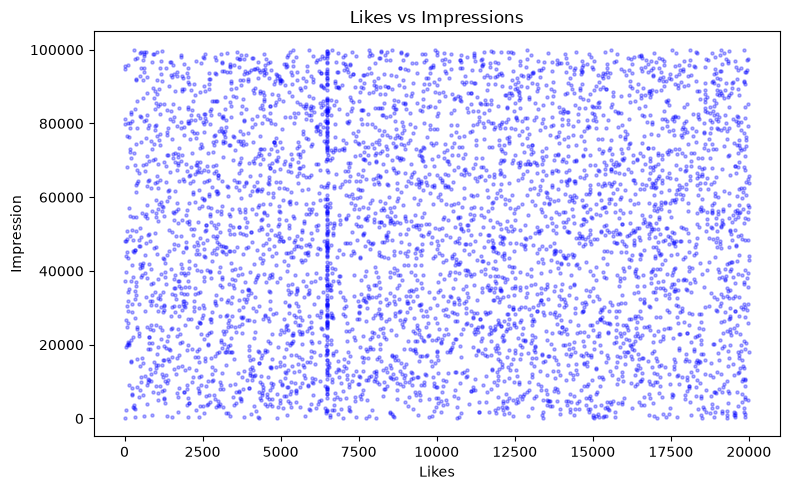

In [18]:
plt.figure(figsize=(8,5))
plt.scatter(df["likes"],df["impression_count"],alpha=0.3,s=5,color="blue")
plt.xlabel("Likes")
plt.ylabel("Impression")
plt.title("Likes vs Impressions")
plt.tight_layout()
plt.show()


### no major correlation. So not considering this plot

##### 1) Line: daily engagement trend

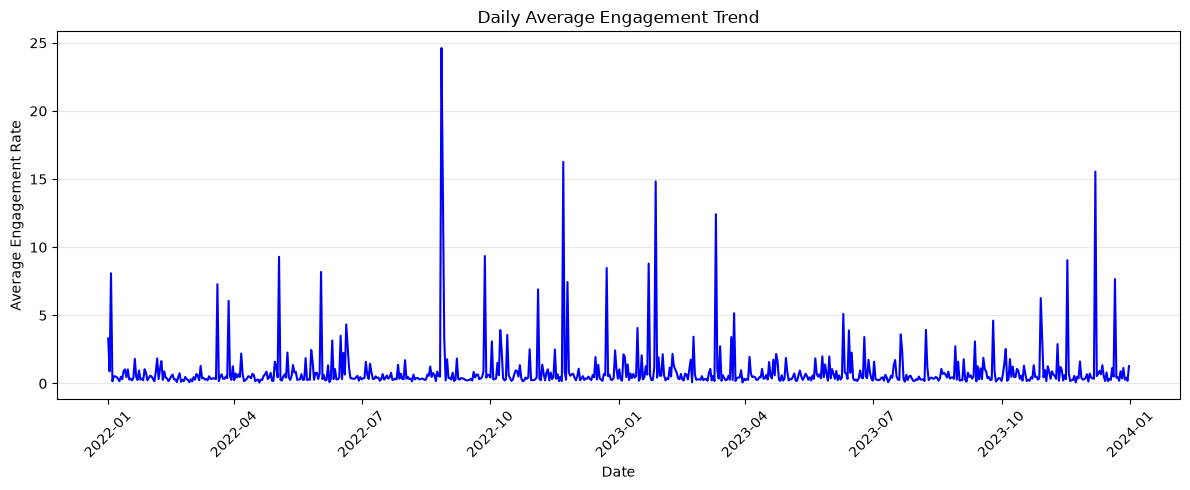

In [20]:
plt.figure(figsize=(12, 5))
df["date"] = df["posted_at"].dt.date
daily_avg = df.groupby("date")["engagement_rate"].mean().reset_index()
plt.plot(daily_avg["date"], daily_avg["engagement_rate"], color="blue", linewidth=1.5, label="Daily Avg")
plt.xlabel("Date")
plt.ylabel("Average Engagement Rate")
plt.title("Daily Average Engagement Trend")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

##### Daily average engagement stays consistently below 10, punctuated by occasional viral spikes that peak near 25 in late 2022.

#### 2)Bar: posts by category

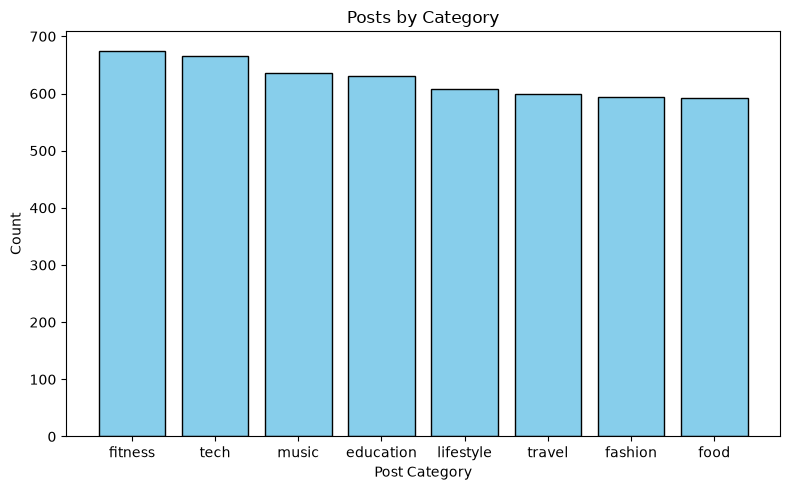

In [24]:
category_counts = df["post_category"].value_counts()
plt.figure(figsize=(8, 5))
plt.bar(category_counts.index, category_counts.values, color="skyblue",edgecolor="black")
plt.xlabel("Post Category")
plt.ylabel("Count")
plt.title("Posts by Category")
plt.tight_layout()
plt.show()

#### Fitness is the top posting category . But every category has a significant amount of posts.

#### 3)Pie: gender distribution

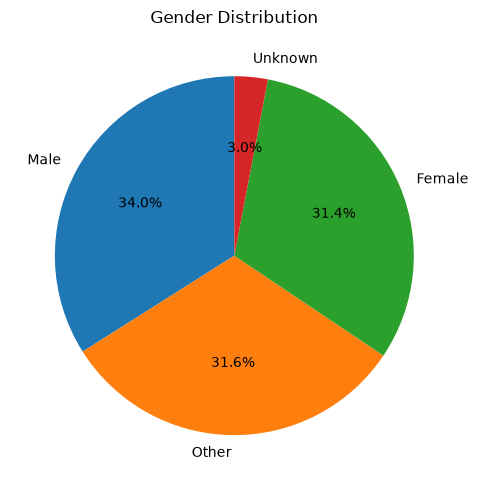

In [25]:
gender_counts = df["gender"].value_counts()
plt.figure(figsize=(5, 5))
plt.pie(gender_counts.values,labels=gender_counts.index,autopct="%1.1f%%",startangle=90)
plt.title("Gender Distribution")
plt.tight_layout()
plt.show()

##### There is approximately equal participation from all genders

#### 4) Histogram: age

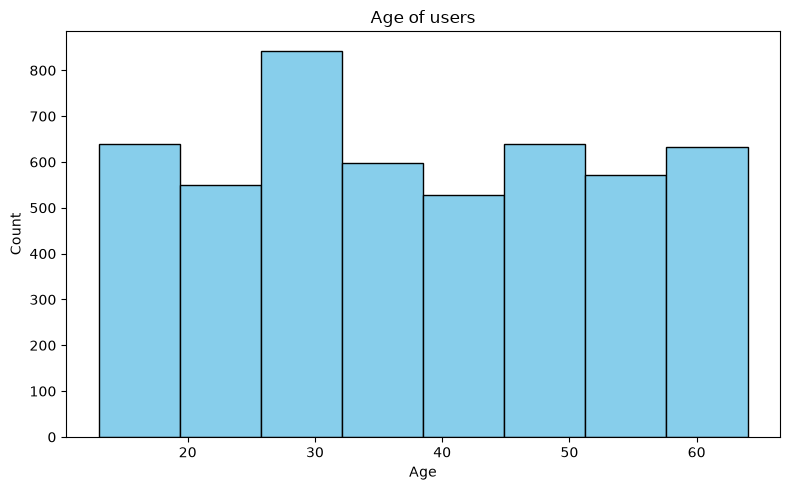

In [51]:
plt.figure(figsize=(8, 5))
plt.hist(df["age"],bins=8, edgecolor="black", color="skyblue")
plt.xlabel("Age")
plt.ylabel("Count")
plt.title("Age of users")
plt.tight_layout()
plt.show()

##### Most users are from the age group 25-35

#### 5)Box: engagement rate

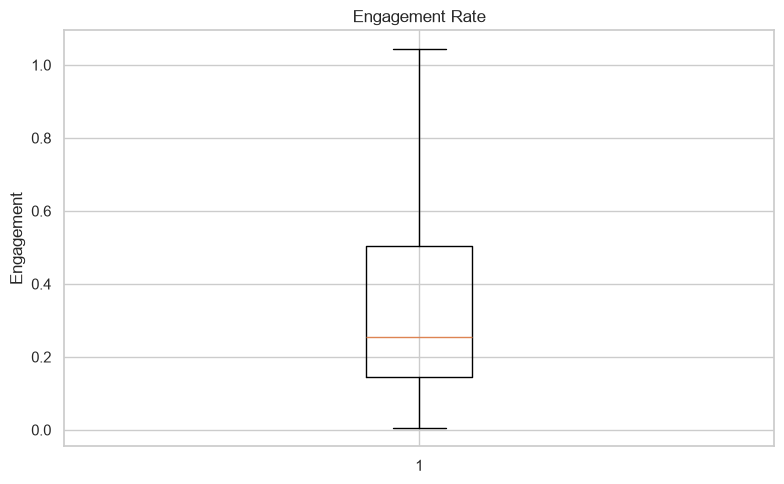

In [62]:
plt.figure(figsize=(8, 5))
plt.boxplot(df["engagement_rate"],showfliers=False)
plt.ylabel("Engagement")
plt.title("Engagement Rate")
plt.tight_layout()
plt.show()

#### The interquartile range spans from roughly 0.15 to 0.50. The median engagement rate is around 0.3 . We have already got te mean engagement rate as 0.25 from statistical analysis

In [24]:
import seaborn as sns

##### 6) Count plot: post type

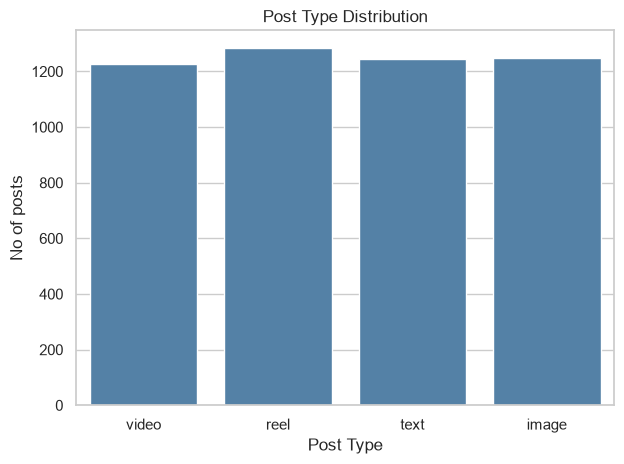

In [68]:
sns.set_theme(style="whitegrid")
sns.countplot(data=df,x="post_type",color="steelblue")
plt.xlabel("Post Type")
plt.ylabel("No of posts")
plt.title("Post Type Distribution")
plt.tight_layout()
plt.show()

##### Reel is the maximum posted post_type.

#### 7) Bar plot: avg likes by category

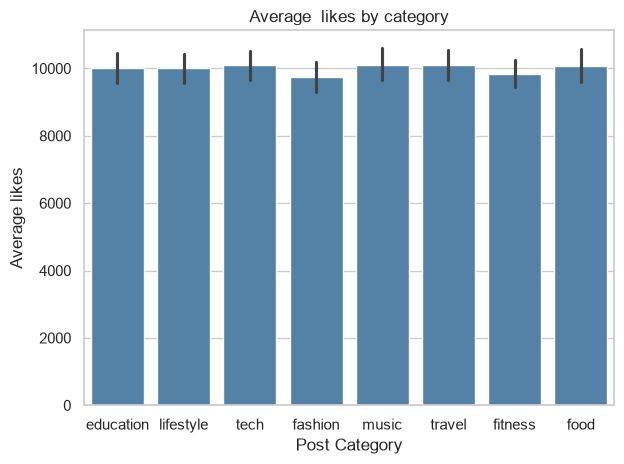

In [71]:
sns.set_theme(style="whitegrid")
sns.barplot(data=df,x="post_category",y="likes",color="steelblue")
plt.xlabel("Post Category")
plt.ylabel("Average likes")
plt.title("Average  likes by category")
plt.tight_layout()
plt.show()

##### Least average  likes is for the genre Fashion.

#### 8) Violin: followers vs sentiment

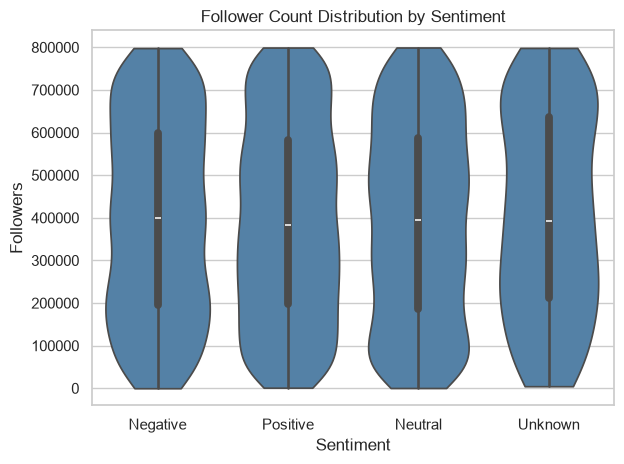

In [31]:
sns.set_theme(style="whitegrid")
sns.violinplot(data=df,y="follower_count",x="sentiment",color="steelblue",cut=0)
plt.ylabel("Followers")
plt.xlabel("Sentiment")
plt.title("Follower Count Distribution by Sentiment")
plt.tight_layout()
plt.show()

##### Follower counts are uniformly distributed between 0 and 800,000 with an identical median of roughly 400,000 across all four sentiment categories. Here cut is used as the plot initially showed negtaive folowers due to smoothing even though the data doesnt have negative value.

#### 9) Pair plot: numeric features

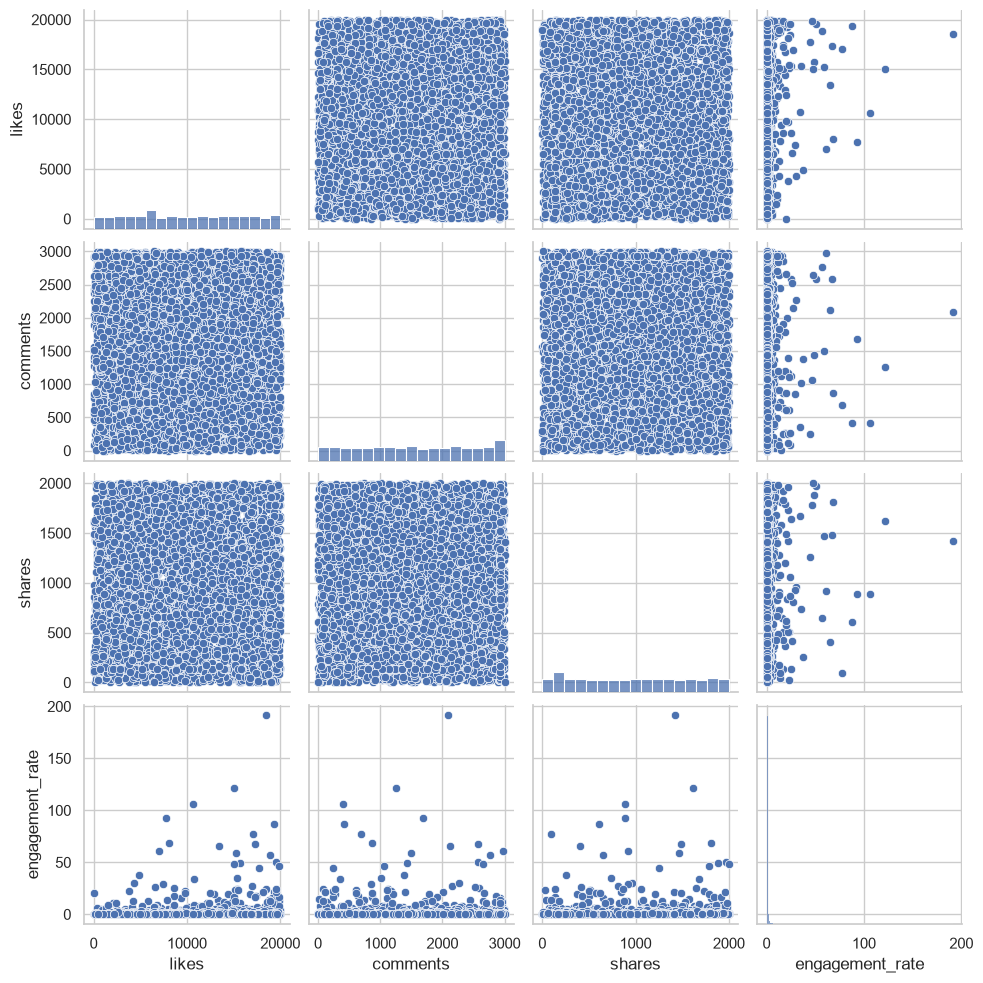

In [37]:
sns.set_theme(style="whitegrid")
numeric_df = df[ ["likes", "comments", "shares", "engagement_rate"]]
sns.pairplot(numeric_df)
plt.show()

##### The data user interactions (likes, comments, shares) share zero mathematical relationship with each other or with the engagement_rate.

#### 10) Heatmap: correlation matrix

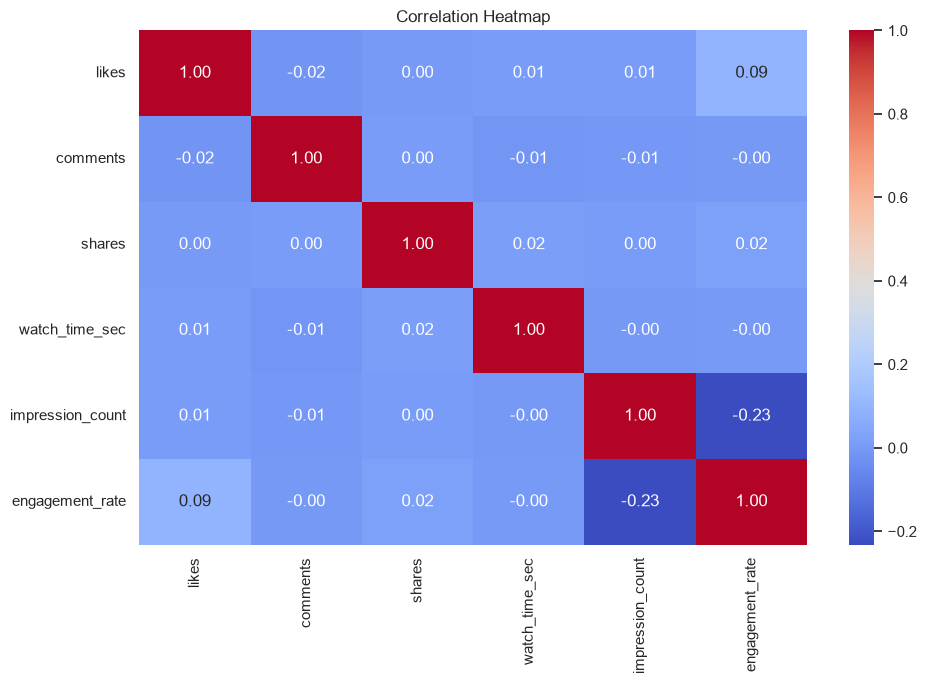

In [20]:
sns.set_theme(style="white")
numeric_df = df[["likes", "comments", "shares", "watch_time_sec", "impression_count", "engagement_rate"]]
corr_matrix = numeric_df.corr()
plt.figure(figsize=(10, 7))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

##### * No relationship among interactions: The correlation scores between likes, comments, and shares sit at 0.00 to -0.02.
##### * Weakest inverse link: A minor negative correlation of -0.23 exists between impression_count and engagement_rate.
##### * Perfect self-correlation: The diagonal shows a perfect 1.00 score for identical variables matching themselves.
##### * Alligns with te previous correlation matrix.

#### Swarm plot: engagement vs device

C:\Users\Lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 21.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\Lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 26.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\Lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 32.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\Lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 31.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.war

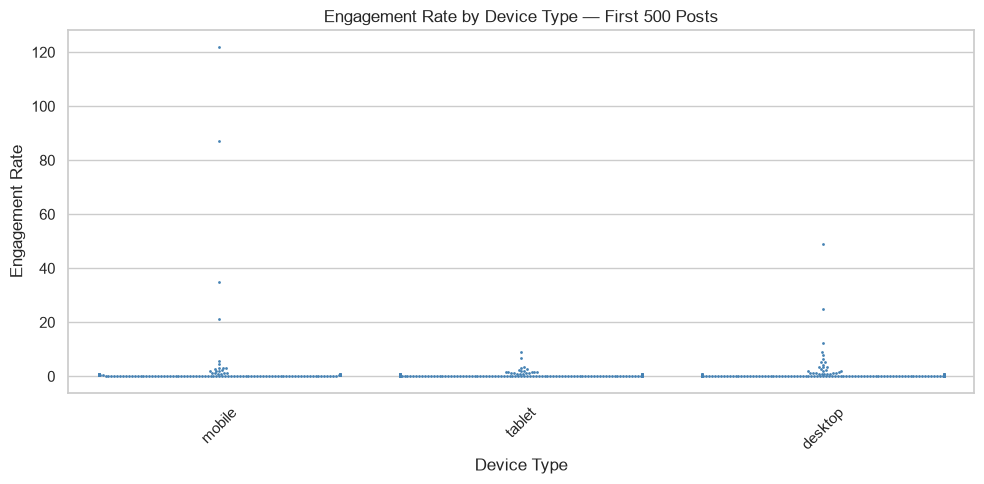

In [25]:
sample_df = df.iloc[:500]
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 5))
sns.swarmplot(
    data=sample_df,
    x="device_type",
    y="engagement_rate",
    color="steelblue",
    size=2)
plt.xlabel("Device Type")
plt.ylabel("Engagement Rate")
plt.title("Engagement Rate by Device Type — First 500 Posts")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

###### Tried swarm plot with whole dataset but its slowing down the sysytem . Therefore tried wit a sample data set . All devices showing nearly same engagement and outliners. Therfore removing this chart from consideration.

In [38]:
import plotly.express as px

#### 11) Plotly interactive chart

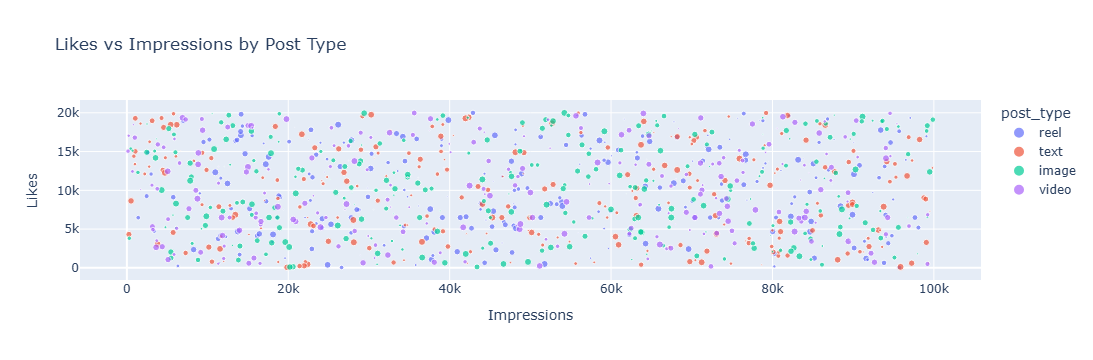

In [35]:
fig = px.scatter(
    df.sample(n=1000, random_state=42),
    x="impression_count",
    y="likes",
    size="comments",
    color="post_type",
    hover_data=["shares", "engagement_rate"],
    title="Likes vs Impressions by Post Type",
    labels={
        "impression_count": "Impressions",
        "likes": "Likes",
        "comments": "Comments"},size_max=5)
fig.show()

##### Impressions do not drive likes, and content formats have zero impact on performance,feels like the dataset is entirely random.

####  More Insights

#### Content Performance

In [26]:
post_type_engagement = df.groupby("post_type")["engagement_rate"].mean().sort_values(ascending=False)
print(post_type_engagement.round(3))

post_type
video    1.122
text     1.065
image    0.896
reel     0.783
Name: engagement_rate, dtype: float64


##### Video has the highest engagement.(note- Previously from groupby summary matrix we obtained video has highest average likes.)

In [30]:
country_engagement = df.groupby("country")["engagement_rate"].mean().sort_values(ascending=False)
print(country_engagement.round(3))

country
Brazil       1.541
Australia    1.324
France       1.146
UAE          1.112
Canada       0.917
UK           0.851
Japan        0.770
Germany      0.759
India        0.655
USA          0.577
Name: engagement_rate, dtype: float64


##### Brazil has highest average engagement rate.(note- Highest avg impression is for India, from groupby summary matrix)

In [31]:
category_engagement = df.groupby("post_category")["engagement_rate"].mean().sort_values(ascending=False)
print(category_engagement.round(3))

post_category
food         1.359
tech         1.160
lifestyle    1.091
music        0.889
fitness      0.866
education    0.844
fashion      0.807
travel       0.702
Name: engagement_rate, dtype: float64


##### Food category showing highest avg engagement . ((1)Fashion and eductaion has highest watch time avg but least avg likes got for Fashion .This summarizes that users repeatedly watching fashion contents are not liking consistantly . (2)Previously obtained that lifestyle video has highest engagement score)

#### User trends

In [60]:
age_engagement = df.groupby("age")["engagement_rate"].mean().sort_index()

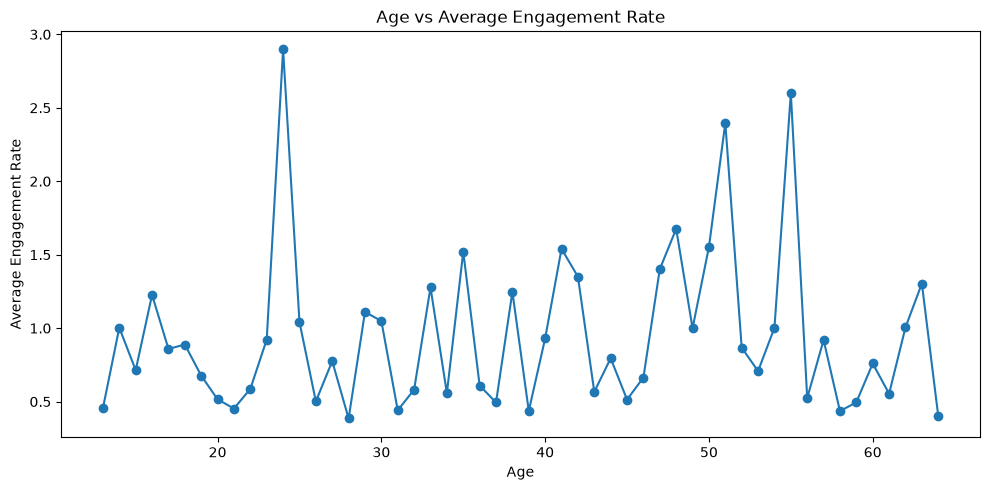

In [61]:
plt.figure(figsize=(10, 5))
plt.plot(age_engagement.index, age_engagement.values, marker="o")
plt.xlabel("Age")
plt.ylabel("Average Engagement Rate")
plt.title("Age vs Average Engagement Rate")
plt.tight_layout()
plt.show()

##### The relationship is non-linear. Engagement does not steadily increase or decrease with age; instead, it exhibits a bimodal fluctuation concentrated in young adulthood and middle age. (aroud 25 , around 55)

In [65]:
performance_summary = df.groupby('is_verified')["engagement_rate"].mean()
print(performance_summary)

is_verified
False    0.954744
True     1.054250
Name: engagement_rate, dtype: float64


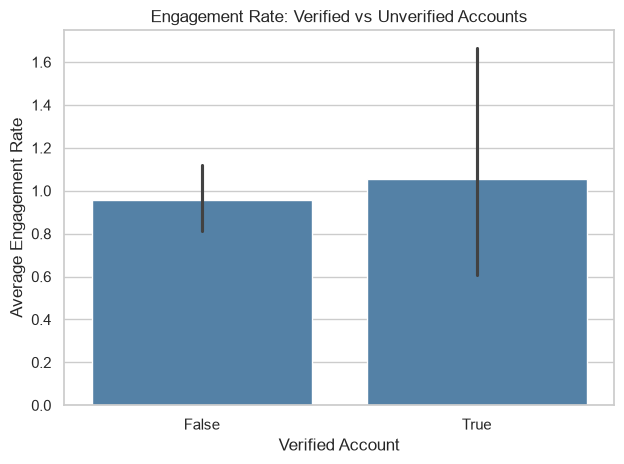

In [66]:
sns.set_theme(style="whitegrid")
sns.barplot(
    data=df,
    x="is_verified",
    y="engagement_rate",
    color="steelblue")
plt.xlabel("Verified Account")
plt.ylabel("Average Engagement Rate")
plt.title("Engagement Rate: Verified vs Unverified Accounts")
plt.tight_layout()
plt.show()

##### Relative to the unverified engagement average, the verified engagement  average is about 10.4% higher

#### Behavioral Insights

In [68]:
df["post_hour"] = df["posted_at"].dt.hour
hourly_impressions = (df.groupby("post_hour")["impression_count"].mean())
print(hourly_impressions.round(2))

post_hour
0    50013.73
Name: impression_count, dtype: float64


##### The best posting hour could not be determined because the dataset contains only dates, without actual posting timestamps. As an alternative, impressions can be analyzed by day of the week to identify which day has the highest average impressions.

In [72]:
df["day_of_week"] = df["posted_at"].dt.day_name()
day_impressions = (
    df.groupby("day_of_week")["impression_count"]
    .mean()
    .sort_values(ascending=False))
print(day_impressions.round(2))

day_of_week
Tuesday      51308.59
Saturday     50945.23
Sunday       50345.67
Monday       50013.22
Wednesday    49857.99
Friday       49430.54
Thursday     48119.29
Name: impression_count, dtype: float64


##### Tuesday is the highest impression yielding weekday.

In [73]:
device_watch_time = (
    df.groupby("device_type")["watch_time_sec"]
    .mean()
    .sort_values(ascending=False))
print(device_watch_time.round(2))

device_type
mobile     4087.83
tablet     3979.74
desktop    3974.79
Name: watch_time_sec, dtype: float64


##### Device type has equal impacts with mobile having a slightly higher impact .

#### Sentiment analysis

In [74]:
sentiment_performance = df.groupby("sentiment").agg(
    post_count=("post_id", "count"),
    avg_likes=("likes", "mean"),
    avg_comments=("comments", "mean"),
    avg_shares=("shares", "mean"),
    avg_engagement_rate=("engagement_rate", "mean"))
print(sentiment_performance.round(2))

           post_count  avg_likes  avg_comments  avg_shares  \
sentiment                                                    
Negative          960   10094.99       1552.02      985.46   
Neutral          1527    9818.90       1566.99      973.67   
Positive         2363   10046.64       1531.05      970.44   
Unknown           150   10448.00       1500.97     1049.77   

           avg_engagement_rate  
sentiment                       
Negative                  1.04  
Neutral                   0.99  
Positive                  0.95  
Unknown                   0.37  


##### (note-We already have the sentiment summary matrix which showed Positive sentimet posts are high but a slightly hike in engagement is noted for negative setiment which is consistent with the current result).

#### Negative posts have a higher average engagement rate (1.04) and more average likes (10,094.99) than neutral posts (0.99 engagement rate and 9,818.90 likes). However, neutral posts generate slightly more average comments (1,566.99) than negative posts (1,552.02). This suggests that negative posts are associated with higher overall engagement, while neutral posts may encourage slightly more discussion.